# Rice Leaf Disease Classification

## Project Introduction

Rice is one of the most important staple food crops worldwide. However, rice plants are susceptible to various diseases that can significantly affect crop yield, quality, and agricultural productivity. Early identification of rice leaf diseases is essential for effective disease management and reducing crop losses.

This project focuses on developing a Deep Learning-based image classification model using Convolutional Neural Networks (CNNs) to identify rice leaf diseases from images.

The dataset contains images belonging to three disease categories:

- **Bacterial Leaf Blight**
- **Brown Spot**
- **Leaf Smut**

The project involves image data exploration, preprocessing, visualization, model development, data augmentation, model evaluation, and performance comparison.

The primary objective is to investigate the effectiveness of CNN-based image classification in identifying rice leaf diseases and evaluate whether data augmentation improves model generalization and classification performance.

In [1]:

# Step 2: Import required libraries

import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from PIL import Image

print("Python Version:", sys.version)
print("NumPy Version:", np.__version__)
print("Pandas Version:", pd.__version__)

print("\nBasic libraries imported successfully!")

Python Version: 3.13.9 | packaged by Anaconda, Inc. | (main, Oct 21 2025, 19:09:58) [MSC v.1929 64 bit (AMD64)]
NumPy Version: 2.3.5
Pandas Version: 2.3.3

Basic libraries imported successfully!


In [2]:

from pathlib import Path

# Main project folder
project_path = Path(
    r"C:\Users\Rakshitha\OneDrive\Desktop\Rice-Leaf-Disease-Classification"
)

# Dataset folder
dataset_path = project_path / "dataset"

# Individual disease image folders
class_paths = {
    "Bacterial Leaf Blight": dataset_path / "Bacterial leaf blight" / "Bacterial leaf blight-20200814T055237Z-001" / "Bacterial leaf blight",
    "Brown Spot": dataset_path / "Brown spot" / "Brown spot-20200814T055208Z-001" / "Brown spot",
    "Leaf Smut": dataset_path / "Leaf smut" / "Leaf smut-20200814T055530Z-001" / "Leaf smut"
}

print("Project folder exists:", project_path.exists())
print("Dataset folder exists:", dataset_path.exists())

print("\nDisease folder verification:")

for disease, folder_path in class_paths.items():
    print(disease, ":", folder_path.exists())

Project folder exists: True
Dataset folder exists: True

Disease folder verification:
Bacterial Leaf Blight : True
Brown Spot : True
Leaf Smut : True


In [3]:

# Step 4: Count images in each disease category

image_extensions = {".jpg", ".jpeg", ".png"}

total_images = 0

for disease, folder_path in class_paths.items():

    images = [
        file for file in folder_path.rglob("*")
        if file.is_file() and file.suffix.lower() in image_extensions
    ]

    image_count = len(images)
    total_images += image_count

    print(f"{disease}: {image_count} images")

print("\nTotal number of images:", total_images)

Bacterial Leaf Blight: 40 images
Brown Spot: 40 images
Leaf Smut: 39 images

Total number of images: 119


In [4]:

# Step 5: Image dimensions and quality analysis

image_records = []
corrupted_images = []

for disease, folder_path in class_paths.items():

    for image_path in folder_path.rglob("*"):

        if image_path.is_file() and image_path.suffix.lower() in image_extensions:

            try:
                with Image.open(image_path) as img:
                    image_records.append({
                        "Disease": disease,
                        "Image_Name": image_path.name,
                        "Width": img.width,
                        "Height": img.height,
                        "Format": img.format,
                        "Mode": img.mode
                    })

            except Exception as error:
                corrupted_images.append(str(image_path))

image_df = pd.DataFrame(image_records)

print("Total readable images:", len(image_df))
print("Total corrupted images:", len(corrupted_images))

print("\nImage dimensions summary:")
print(image_df[["Width", "Height"]].describe())

print("\nImage formats:")
print(image_df["Format"].value_counts())

print("\nImage color modes:")
print(image_df["Mode"].value_counts())

Total readable images: 119
Total corrupted images: 0

Image dimensions summary:
             Width      Height
count   119.000000  119.000000
mean   2383.638655  707.739496
std    1123.528972  311.657582
min     250.000000   71.000000
25%    1074.000000  377.000000
50%    3081.000000  897.000000
75%    3081.000000  897.000000
max    3081.000000  900.000000

Image formats:
Format
JPEG    119
Name: count, dtype: int64

Image color modes:
Mode
RGB    119
Name: count, dtype: int64



## 6. Image Quality and Technical Analysis

### 6.1 Image Readability

- Total readable images: 119
- Total corrupted images: 0
- All 119 images were successfully opened and inspected using the PIL library.

**Observation:** No corrupted or unreadable images were identified.

### 6.2 Image Dimensions

- Minimum dimensions: 250 × 71 pixels
- Maximum dimensions: 3081 × 900 pixels
- Average width: 2383.64 pixels
- Average height: 707.74 pixels

**Observation:** The dataset contains images with varying dimensions and aspect ratios. Image resizing will be required before model training to maintain consistent input dimensions.

### 6.3 Image Formats

- JPEG: 119 images

**Observation:** All images are in JPEG format, providing a consistent image format across the dataset.

### 6.4 Image Color Modes

- RGB: 119 images

**Observation:** All images contain three color channels (Red, Green, and Blue). Therefore, no grayscale image conversion is required at this stage.

### 6.5 Overall Findings

The initial image quality analysis confirms that all 119 available images are readable, use JPEG format, and have RGB color mode. However, image dimensions vary considerably, so resizing and appropriate preprocessing will be performed before model development.

The official project description mentions 120 images, whereas the received dataset contains 119 images. This discrepancy is documented transparently without creating or duplicating any images.


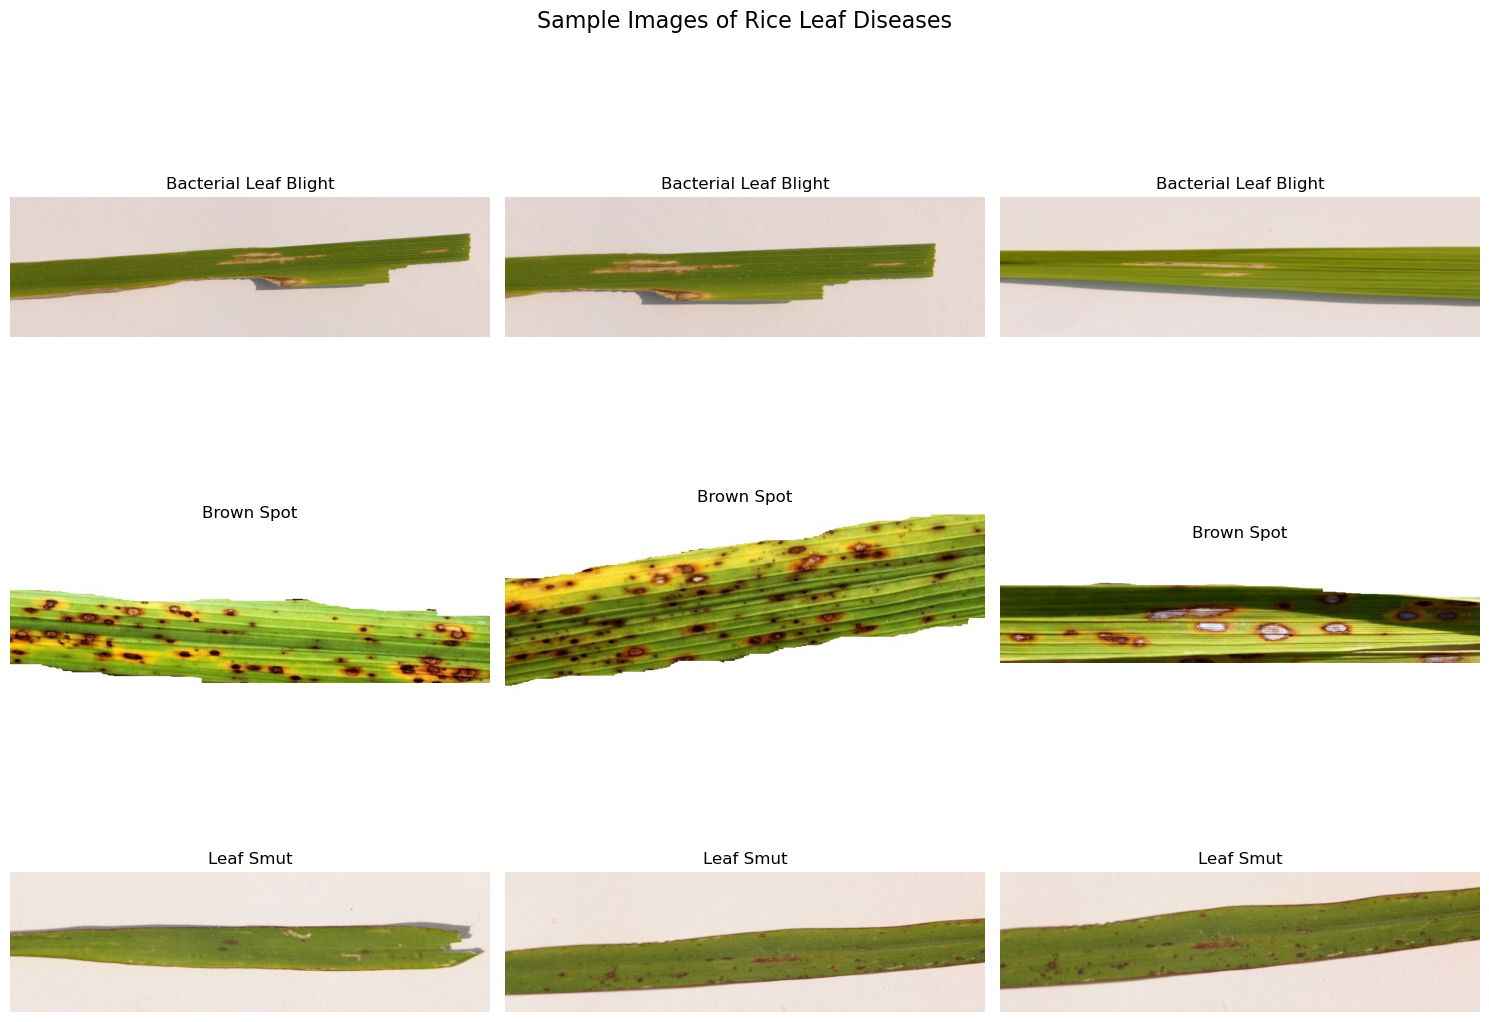

In [5]:

# Step 7: Visualize sample images from all disease categories

fig, axes = plt.subplots(3, 3, figsize=(15, 12))

for row, (disease, folder_path) in enumerate(class_paths.items()):

    image_files = sorted([
        file for file in folder_path.rglob("*")
        if file.is_file() and file.suffix.lower() in image_extensions
    ])

    for col in range(3):
        image_path = image_files[col]

        with Image.open(image_path) as img:
            axes[row, col].imshow(img.copy())

        axes[row, col].set_title(disease)
        axes[row, col].axis("off")

plt.suptitle("Sample Images of Rice Leaf Diseases", fontsize=16)
plt.tight_layout()
plt.show()


## 7. Sample Image Visualization

Nine sample images were visualized from the three rice leaf disease categories, with three images selected from each category.

### Observations

1. Bacterial Leaf Blight: Sample images were visually inspected to observe leaf appearance and disease symptoms.
2. Brown Spot: Sample images were visually inspected to observe visible spots and leaf discoloration.
3. Leaf Smut: Sample images were visually inspected to examine visible disease-related patterns.

### Findings

- Images from all three disease categories were successfully loaded and displayed.
- The visualization confirms that the dataset contains different visual patterns across the three classes.
- Further preprocessing will be required to standardize image dimensions before model training.


Number of images in each disease category:

Disease
Bacterial Leaf Blight    40
Brown Spot               40
Leaf Smut                39
Name: count, dtype: int64

Class distribution percentage:

Disease
Bacterial Leaf Blight    33.61
Brown Spot               33.61
Leaf Smut                32.77
Name: count, dtype: float64


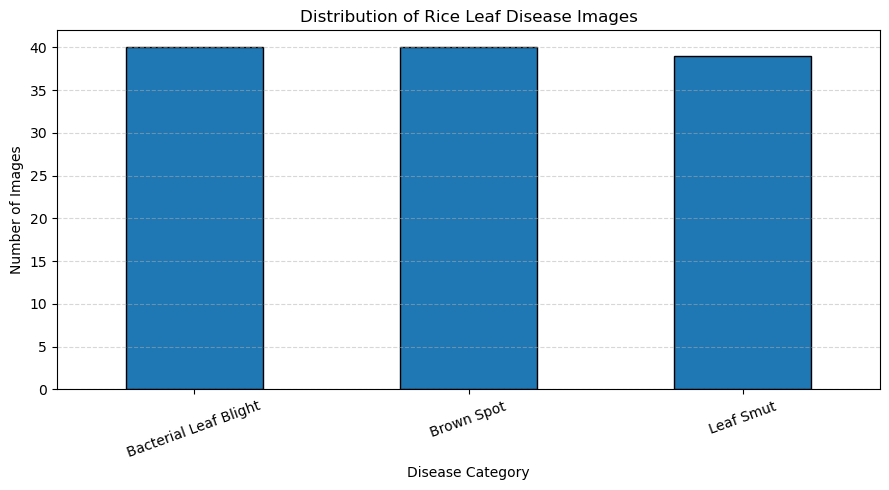

In [6]:

# Step 8: Class Distribution Analysis

class_counts = image_df["Disease"].value_counts()

print("Number of images in each disease category:\n")
print(class_counts)

print("\nClass distribution percentage:\n")
print((class_counts / len(image_df) * 100).round(2))

# Visualize class distribution
plt.figure(figsize=(9, 5))

class_counts.plot(kind="bar", edgecolor="black")

plt.title("Distribution of Rice Leaf Disease Images")
plt.xlabel("Disease Category")
plt.ylabel("Number of Images")
plt.xticks(rotation=20)
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()


## 8. Class Distribution Analysis

The dataset contains three rice leaf disease categories with a total of 119 images.

### Class Distribution

- Bacterial Leaf Blight: 40 images (33.61%)
- Brown Spot: 40 images (33.61%)
- Leaf Smut: 39 images (32.77%)

### Observations

1. Bacterial Leaf Blight and Brown Spot contain 40 images each.
2. Leaf Smut contains 39 images.
3. All three categories have nearly equal representation.
4. The dataset is approximately balanced, with only one image difference between classes.

### Conclusion

The dataset does not show significant class imbalance. Therefore, additional class balancing techniques are not immediately required. Model performance will be evaluated separately for each disease category.


In [7]:

# Step 9: Image Dimensions Analysis by Disease Category

dimension_summary = image_df.groupby("Disease").agg(
    Image_Count=("Image_Name", "count"),
    Average_Width=("Width", "mean"),
    Average_Height=("Height", "mean"),
    Minimum_Width=("Width", "min"),
    Maximum_Width=("Width", "max"),
    Minimum_Height=("Height", "min"),
    Maximum_Height=("Height", "max")
)

print("Image Dimension Summary by Disease Category:\n")
print(dimension_summary.round(2))

Image Dimension Summary by Disease Category:

                       Image_Count  Average_Width  Average_Height  \
Disease                                                             
Bacterial Leaf Blight           40        3081.00          897.00   
Brown Spot                      40        1951.28          589.17   
Leaf Smut                       39        2111.85          635.23   

                       Minimum_Width  Maximum_Width  Minimum_Height  \
Disease                                                               
Bacterial Leaf Blight           3081           3081             897   
Brown Spot                       286           3081              88   
Leaf Smut                        250           3081              71   

                       Maximum_Height  
Disease                                
Bacterial Leaf Blight             897  
Brown Spot                        900  
Leaf Smut                         897  



## 9. Image Dimension Analysis by Disease Category

Image dimensions were analyzed separately for all three disease categories.

### Observations

1. Bacterial Leaf Blight:
   - All 40 images have dimensions of 3081 × 897 pixels.
   - No variation in image dimensions was observed.

2. Brown Spot:
   - Average width: 1951.28 pixels.
   - Average height: 589.17 pixels.
   - Image dimensions vary from 286 × 88 to 3081 × 900 pixels.

3. Leaf Smut:
   - Average width: 2111.85 pixels.
   - Average height: 635.23 pixels.
   - Image dimensions vary from 250 × 71 to 3081 × 897 pixels.

### Conclusion

The dataset contains considerable variation in image dimensions across disease categories. Therefore, image resizing and consistent preprocessing will be required before model training. Original images will be preserved without modification.


Aspect Ratio Summary:

                       count  mean   std   min   25%   50%   75%   max
Disease                                                               
Bacterial Leaf Blight   40.0  3.43  0.00  3.43  3.43  3.43  3.43  3.43
Brown Spot              40.0  3.28  0.75  1.33  3.30  3.43  3.43  5.30
Leaf Smut               39.0  3.25  0.84  1.25  3.43  3.43  3.43  5.03


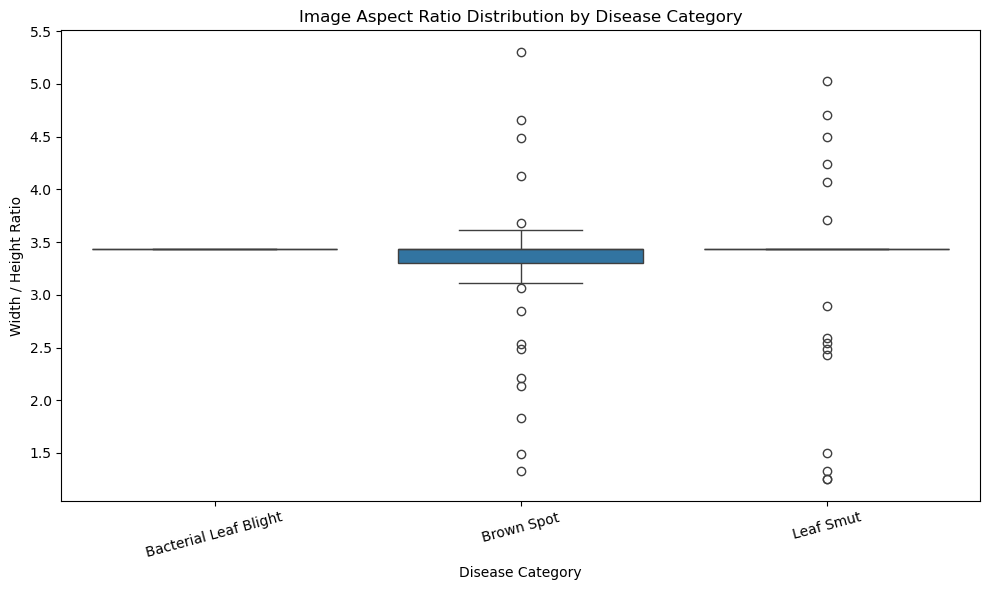

In [8]:

# Step 10: Image Aspect Ratio Analysis

image_df["Aspect_Ratio"] = image_df["Width"] / image_df["Height"]

print("Aspect Ratio Summary:\n")
print(image_df.groupby("Disease")["Aspect_Ratio"].describe().round(2))

# Visualize aspect ratio distribution
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=image_df,
    x="Disease",
    y="Aspect_Ratio"
)

plt.title("Image Aspect Ratio Distribution by Disease Category")
plt.xlabel("Disease Category")
plt.ylabel("Width / Height Ratio")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


## 10. Image Aspect Ratio Analysis

Aspect ratios were calculated by dividing image width by image height.

### Observations

1. Bacterial Leaf Blight:
   - All 40 images have a consistent aspect ratio of approximately 3.43.

2. Brown Spot:
   - Aspect ratios range from 1.33 to 5.30.
   - Considerable variation in image proportions was observed.

3. Leaf Smut:
   - Aspect ratios range from 1.25 to 5.03.
   - Image proportions also vary considerably.

### Conclusion

The dataset contains variations in image aspect ratios, particularly in the Brown Spot and Leaf Smut categories. Direct resizing may distort the original image proportions. Therefore, appropriate image resizing techniques will be considered during preprocessing.


In [9]:

# Step 12: Duplicate Image Detection

import hashlib
from collections import defaultdict

image_hashes = defaultdict(list)

for disease, folder_path in class_paths.items():

    for image_path in folder_path.rglob("*"):

        if image_path.is_file() and image_path.suffix.lower() in image_extensions:

            with open(image_path, "rb") as file:
                file_hash = hashlib.sha256(file.read()).hexdigest()

            image_hashes[file_hash].append(
                (disease, image_path.name)
            )

duplicate_groups = {
    file_hash: files
    for file_hash, files in image_hashes.items()
    if len(files) > 1
}

print("Total images checked:", sum(len(files) for files in image_hashes.values()))
print("Unique image files:", len(image_hashes))
print("Duplicate groups found:", len(duplicate_groups))

if duplicate_groups:
    print("\nDuplicate image details:")
    for files in duplicate_groups.values():
        print(files)
else:
    print("\nNo exact duplicate images found.")

Total images checked: 119
Unique image files: 119
Duplicate groups found: 0

No exact duplicate images found.



## 11. Duplicate Image Detection

Exact duplicate images were identified using the SHA-256 hashing technique.

### Results

- Total images checked: 119
- Unique image files: 119
- Exact duplicate groups: 0

### Conclusion

No exact duplicate image files were identified in the dataset. All 119 image files have unique SHA-256 hashes. Therefore, no exact file duplication was detected during this analysis.


In [10]:

# Step 13: Image Color Analysis

color_records = []

for disease, folder_path in class_paths.items():

    for image_path in folder_path.rglob("*"):

        if image_path.is_file() and image_path.suffix.lower() in image_extensions:

            with Image.open(image_path) as img:
                # Resize temporarily to reduce computation
                img = img.convert("RGB").resize((128, 128))

                pixels = np.array(img)

                color_records.append({
                    "Disease": disease,
                    "Red_Mean": pixels[:, :, 0].mean(),
                    "Green_Mean": pixels[:, :, 1].mean(),
                    "Blue_Mean": pixels[:, :, 2].mean()
                })

color_df = pd.DataFrame(color_records)

print("Average RGB values by disease category:\n")
print(
    color_df.groupby("Disease")[
        ["Red_Mean", "Green_Mean", "Blue_Mean"]
    ].mean().round(2)
)

Average RGB values by disease category:

                       Red_Mean  Green_Mean  Blue_Mean
Disease                                               
Bacterial Leaf Blight    194.20      188.88     152.22
Brown Spot               191.27      189.44     126.63
Leaf Smut                180.10      181.92     141.38



## 12. RGB Color Analysis

The average Red, Green, and Blue channel intensities were calculated for all three disease categories. Images were temporarily resized to 128 × 128 pixels for this analysis.

### Observations

1. Bacterial Leaf Blight:
   - Average Red: 194.20
   - Average Green: 188.88
   - Average Blue: 152.22

2. Brown Spot:
   - Average Red: 191.27
   - Average Green: 189.44
   - Average Blue: 126.63

3. Leaf Smut:
   - Average Red: 180.10
   - Average Green: 181.92
   - Average Blue: 141.38

### Conclusion

The three disease categories show differences in their average RGB channel intensities. These color statistics provide preliminary information about image characteristics. However, classification will depend on learning relevant visual features rather than relying only on average color values.


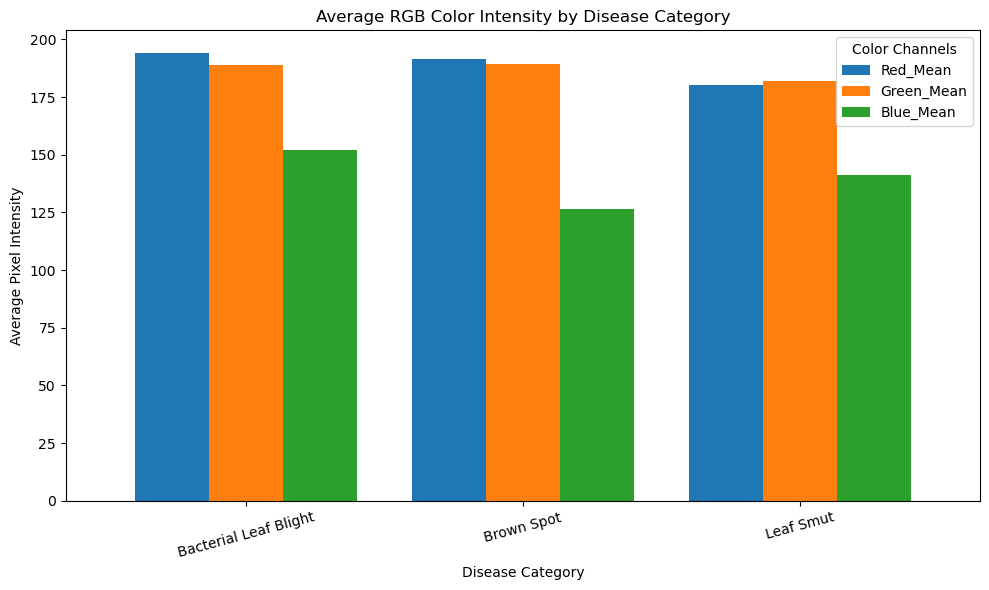

In [11]:

# Step 14: Visualize average RGB values by disease category

rgb_summary = color_df.groupby("Disease")[
    ["Red_Mean", "Green_Mean", "Blue_Mean"]
].mean()

rgb_summary.plot(
    kind="bar",
    figsize=(10, 6),
    width=0.8
)

plt.title("Average RGB Color Intensity by Disease Category")
plt.xlabel("Disease Category")
plt.ylabel("Average Pixel Intensity")
plt.xticks(rotation=15)
plt.legend(title="Color Channels")
plt.tight_layout()
plt.show()


### RGB Color Comparison Visualization

The average Red, Green, and Blue (RGB) channel intensities were calculated for each disease category and visualized using a grouped bar chart.

**Observations:**
- Bacterial Leaf Blight showed the highest average red intensity.
- Brown Spot showed the highest average green intensity and the lowest average blue intensity.
- Leaf Smut showed comparatively lower average red and green intensities.
- These values provide a basic understanding of image color distribution across the three disease categories.

**Conclusion:**

RGB analysis helps understand the overall color characteristics of the dataset. However, average RGB values alone are not sufficient to distinguish rice leaf diseases. Further image processing and model-based analysis are required.


Number of unusual aspect ratio images: 9


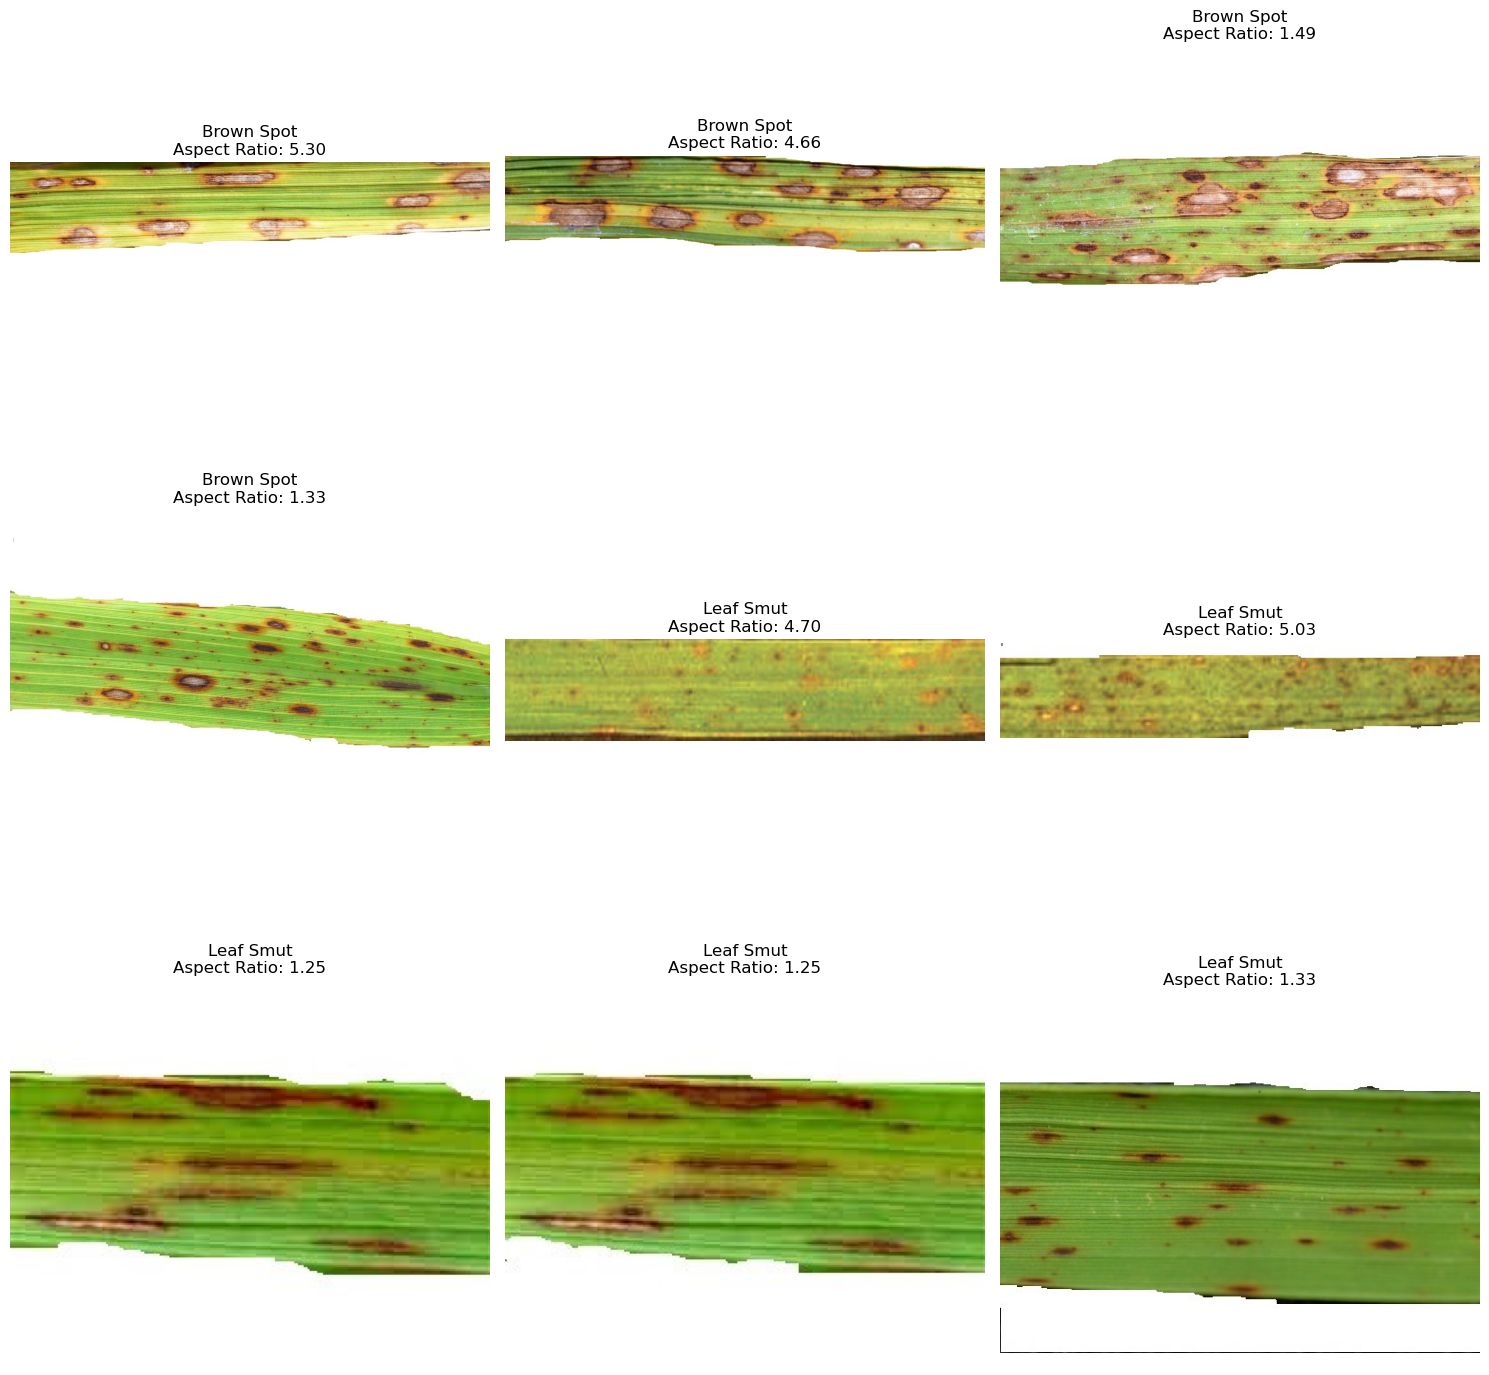

In [12]:

# Step 15: Inspect images with unusual aspect ratios

outlier_images = []

for disease, folder_path in class_paths.items():
    for image_path in folder_path.rglob("*"):
        if image_path.is_file() and image_path.suffix.lower() in image_extensions:
            with Image.open(image_path) as img:
                aspect_ratio = img.width / img.height

                if aspect_ratio <= 1.5 or aspect_ratio >= 4.5:
                    outlier_images.append({
                        "Disease": disease,
                        "Image_Path": image_path,
                        "Aspect_Ratio": aspect_ratio
                    })

print("Number of unusual aspect ratio images:", len(outlier_images))

# Display the unusual images
if outlier_images:
    columns = 3
    rows = (len(outlier_images) + columns - 1) // columns

    plt.figure(figsize=(15, 5 * rows))

    for i, record in enumerate(outlier_images):
        with Image.open(record["Image_Path"]) as img:
            plt.subplot(rows, columns, i + 1)
            plt.imshow(img)
            plt.title(
                f'{record["Disease"]}\nAspect Ratio: {record["Aspect_Ratio"]:.2f}'
            )
            plt.axis("off")

    plt.tight_layout()
    plt.show()
else:
    print("No unusual aspect ratio images found.")


### Image Inspection and Aspect Ratio Findings

A total of 9 images with unusual aspect ratios were visually inspected.

**Observations:**
- Several images contain elongated rice leaf regions.
- Some images have very wide aspect ratios.
- The leaf regions and disease symptoms are visually present.
- No images were removed based on aspect ratio alone.

**Conclusion:**

Since the images have different dimensions and aspect ratios, resizing them directly into a square shape may distort the leaf structures. Therefore, aspect-ratio-preserving resizing with padding will be considered during image preprocessing. Original images will remain unchanged.


In [13]:

# Step 18: Image preprocessing using resize and padding

from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

TARGET_SIZE = (224, 224)

processed_images = []
image_labels = []

for disease, folder_path in class_paths.items():

    for image_path in sorted(folder_path.rglob("*")):

        if image_path.is_file() and image_path.suffix.lower() in image_extensions:

            with Image.open(image_path) as img:

                # Convert image to RGB
                img = img.convert("RGB")

                # Resize while preserving aspect ratio
                img.thumbnail(TARGET_SIZE, Image.Resampling.LANCZOS)

                # Create a white background canvas
                canvas = Image.new("RGB", TARGET_SIZE, (255, 255, 255))

                # Calculate position to center the resized image
                x_offset = (TARGET_SIZE[0] - img.width) // 2
                y_offset = (TARGET_SIZE[1] - img.height) // 2

                # Paste resized image onto the canvas
                canvas.paste(img, (x_offset, y_offset))

                # Convert image into NumPy array
                processed_images.append(np.array(canvas))
                image_labels.append(disease)

# Convert lists into NumPy arrays
X = np.array(processed_images)
y = np.array(image_labels)

print("Image preprocessing completed successfully!")
print("Processed image shape:", X.shape)
print("Labels shape:", y.shape)
print("Target image size:", TARGET_SIZE)
print("Total processed images:", len(X))

Image preprocessing completed successfully!
Processed image shape: (119, 224, 224, 3)
Labels shape: (119,)
Target image size: (224, 224)
Total processed images: 119


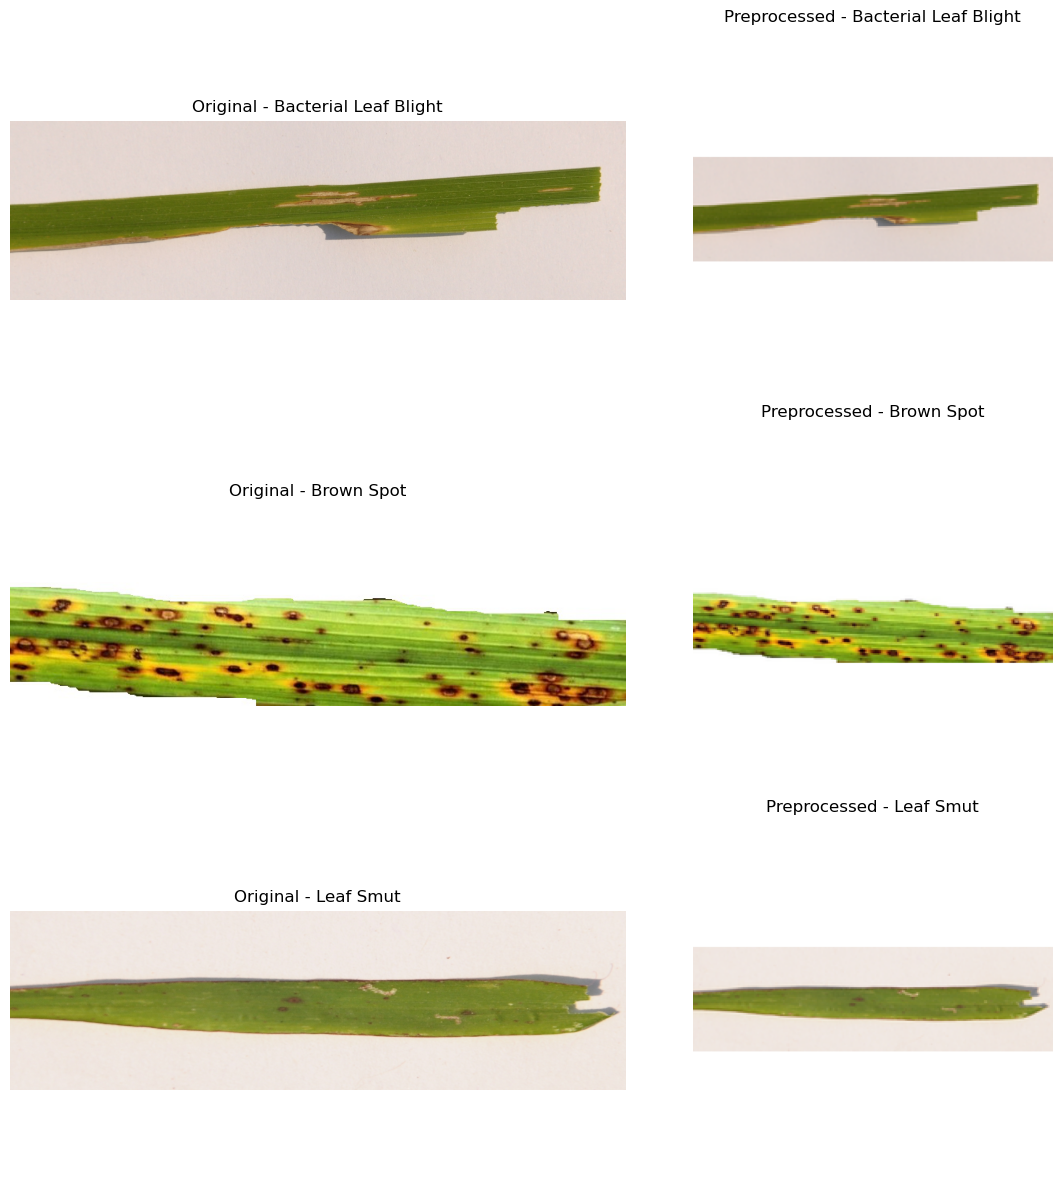

In [14]:

# Step 19: Compare original and preprocessed images

plt.figure(figsize=(12, 12))

for i, disease in enumerate(class_paths.keys()):

    # Get the first image of each disease category
    original_path = sorted(
        [
            p for p in class_paths[disease].rglob("*")
            if p.is_file() and p.suffix.lower() in image_extensions
        ]
    )[0]

    # Find its corresponding preprocessed image
    image_index = np.where(y == disease)[0][0]

    # Display original image
    with Image.open(original_path) as img:
        plt.subplot(3, 2, 2 * i + 1)
        plt.imshow(img.convert("RGB"))
        plt.title(f"Original - {disease}")
        plt.axis("off")

    # Display preprocessed image
    plt.subplot(3, 2, 2 * i + 2)
    plt.imshow(X[image_index])
    plt.title(f"Preprocessed - {disease}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [15]:

# Step 20: Split dataset into training, validation and testing sets

from sklearn.model_selection import train_test_split

# First split: 70% training and 30% temporary data
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Second split: Divide temporary data equally into validation and testing
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Dataset splitting completed successfully!")

print("\nTraining set:", X_train.shape)
print("Validation set:", X_val.shape)
print("Testing set:", X_test.shape)

print("\nTotal images:", len(X_train) + len(X_val) + len(X_test))

print("\nTraining class distribution:")
print(pd.Series(y_train).value_counts())

print("\nValidation class distribution:")
print(pd.Series(y_val).value_counts())

print("\nTesting class distribution:")
print(pd.Series(y_test).value_counts())

Dataset splitting completed successfully!

Training set: (83, 224, 224, 3)
Validation set: (18, 224, 224, 3)
Testing set: (18, 224, 224, 3)

Total images: 119

Training class distribution:
Brown Spot               28
Bacterial Leaf Blight    28
Leaf Smut                27
Name: count, dtype: int64

Validation class distribution:
Leaf Smut                6
Brown Spot               6
Bacterial Leaf Blight    6
Name: count, dtype: int64

Testing class distribution:
Leaf Smut                6
Brown Spot               6
Bacterial Leaf Blight    6
Name: count, dtype: int64



### Dataset Splitting

The preprocessed dataset containing 119 images was divided into three subsets using stratified sampling.

**Dataset Distribution:**

- Training set: 83 images (approximately 70%)
- Validation set: 18 images (approximately 15%)
- Testing set: 18 images (approximately 15%)

**Observations:**
- All three disease categories are represented in each subset.
- Training data contains 28 Bacterial Leaf Blight, 28 Brown Spot, and 27 Leaf Smut images.
- Validation and testing sets contain 6 images from each disease category.
- Stratified sampling helped maintain balanced class representation.

**Conclusion:**

The dataset was successfully divided into training, validation, and testing sets. The training set will be used to train models, the validation set to monitor model performance, and the testing set for final evaluation.


In [16]:

# Step 22: Normalize image pixel values

X_train_scaled = X_train.astype("float32") / 255.0
X_val_scaled = X_val.astype("float32") / 255.0
X_test_scaled = X_test.astype("float32") / 255.0

print("Image normalization completed successfully!")

print("Training pixel range:",
      X_train_scaled.min(), "to", X_train_scaled.max())

print("Validation pixel range:",
      X_val_scaled.min(), "to", X_val_scaled.max())

print("Testing pixel range:",
      X_test_scaled.min(), "to", X_test_scaled.max())

Image normalization completed successfully!
Training pixel range: 0.0 to 1.0
Validation pixel range: 0.0 to 1.0
Testing pixel range: 0.0 to 1.0



### Image Normalization

The pixel values of the training, validation, and testing images were normalized by dividing each pixel value by 255.

**Observations:**
- Original pixel values ranged from 0 to 255.
- Normalized pixel values range from 0.0 to 1.0.
- Normalization was applied separately to the training, validation, and testing datasets.

**Conclusion:**

Image normalization was successfully completed. All image subsets are now represented with pixel values between 0 and 1, making them suitable for neural network model training.


In [17]:

# Step 24: Encode disease labels

from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(y_train)
y_val_encoded = label_encoder.transform(y_val)
y_test_encoded = label_encoder.transform(y_test)

print("Label encoding completed successfully!")

print("\nDisease label mapping:")

for index, disease in enumerate(label_encoder.classes_):
    print(f"{disease} = {index}")

print("\nEncoded training labels shape:", y_train_encoded.shape)
print("Encoded validation labels shape:", y_val_encoded.shape)
print("Encoded testing labels shape:", y_test_encoded.shape)

Label encoding completed successfully!

Disease label mapping:
Bacterial Leaf Blight = 0
Brown Spot = 1
Leaf Smut = 2

Encoded training labels shape: (83,)
Encoded validation labels shape: (18,)
Encoded testing labels shape: (18,)



### Disease Label Encoding

The disease category labels were converted into numerical values using the LabelEncoder from Scikit-learn.

**Label Mapping:**

- Bacterial Leaf Blight: 0
- Brown Spot: 1
- Leaf Smut: 2

**Observations:**
- Training labels: 83
- Validation labels: 18
- Testing labels: 18

**Conclusion:**

Label encoding was successfully completed. All three disease categories were converted into numerical labels for model development.


In [18]:

# Step 26: Check deep learning library availability

import importlib.util
import sys

print("Python Version:", sys.version)

libraries = ["tensorflow", "keras", "torch", "sklearn"]

for library in libraries:
    available = importlib.util.find_spec(library) is not None
    print(f"{library}: {'Installed' if available else 'Not Installed'}")

Python Version: 3.13.9 | packaged by Anaconda, Inc. | (main, Oct 21 2025, 19:09:58) [MSC v.1929 64 bit (AMD64)]
tensorflow: Installed
keras: Installed
torch: Not Installed
sklearn: Installed


### TensorFlow Installation

TensorFlow 2.21.0 was installed successfully in the development environment.

Installation command:

`pip install tensorflow==2.21.0`

In [19]:

# Step 28: Verify TensorFlow and Keras Installation

import tensorflow as tf
import keras

print("TensorFlow Version:", tf.__version__)
print("Keras Version:", keras.__version__)

print("\nAvailable devices:")
print(tf.config.list_physical_devices())

print("\nTensorFlow and Keras imported successfully!")

TensorFlow Version: 2.21.0
Keras Version: 3.15.1

Available devices:
[PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]

TensorFlow and Keras imported successfully!



### Deep Learning Environment Setup

TensorFlow and Keras were successfully installed and imported.

**Environment Details:**
- Python Version: 3.13.9
- TensorFlow Version: 2.21.0
- Keras Version: 3.15.1
- Execution Device: CPU

**Observation:**

TensorFlow detected the CPU as the available execution device. GPU support is unavailable in the current native Windows environment.

**Conclusion:**

The deep learning environment was successfully configured, and it is ready for CNN model development.


In [20]:

# Step 30: Import deep learning libraries

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models

from sklearn.metrics import (
    classification_report,
    confusion_matrix
)

print("Deep learning and evaluation libraries imported successfully!")

Deep learning and evaluation libraries imported successfully!


In [21]:

# Step 31: Build CNN model architecture

cnn_model = models.Sequential([
    # Input layer
    layers.Input(shape=(224, 224, 3)),

    # First convolution block
    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Second convolution block
    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Third convolution block
    layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Classification layers
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(3, activation="softmax")
])

# Display model architecture
cnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 224, 224, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 112, 112, 32)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 112, 112, 64)        │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 56, 56, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 56, 56, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 28, 28, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 100352)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │      12,845,184 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 3)                   │             387 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 12,938,819 (49.36 MB)

 Trainable params: 12,938,819 (49.36 MB)

 Non-trainable params: 0 (0.00 B)

In [22]:

# Step 32: Compile CNN model

cnn_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("CNN model compiled successfully!")

CNN model compiled successfully!



**Environment Note:**

TensorFlow displayed a GPU availability warning because the project is running on native Windows. CPU execution is available, and the CNN model compiled successfully. Model development will continue using CPU execution.


In [23]:

# Step 33: Train the CNN model

history_cnn = cnn_model.fit(
    X_train_scaled,
    y_train_encoded,
    validation_data=(X_val_scaled, y_val_encoded),
    epochs=15,
    batch_size=8,
    verbose=1
)

Epoch 1/15
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 186ms/step - accuracy: 0.3373 - loss: 1.2033 - val_accuracy: 0.3333 - val_loss: 1.1141
Epoch 2/15
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 168ms/step - accuracy: 0.4096 - loss: 1.0704 - val_accuracy: 0.3333 - val_loss: 1.0871
Epoch 3/15
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 164ms/step - accuracy: 0.4096 - loss: 1.0913 - val_accuracy: 0.4444 - val_loss: 1.0603
Epoch 4/15
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 161ms/step - accuracy: 0.4337 - loss: 1.0435 - val_accuracy: 0.5000 - val_loss: 1.0367
Epoch 5/15
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 159ms/step - accuracy: 0.4940 - loss: 1.0401 - val_accuracy: 0.6111 - val_loss: 1.0054
Epoch 6/15
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 167ms/step - accuracy: 0.5181 - loss: 1.0470 - val_accuracy: 0.5000 - val_loss: 0.9797
Epoch 7/15
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 160ms/step - accuracy: 0.4096 - loss: 0.9958 - val_accuracy: 0.6111 - val_loss: 0.9591
Epoch 8/15
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 158ms/step - accuracy: 0.5301 - loss: 0.9676 - val_accuracy: 0.

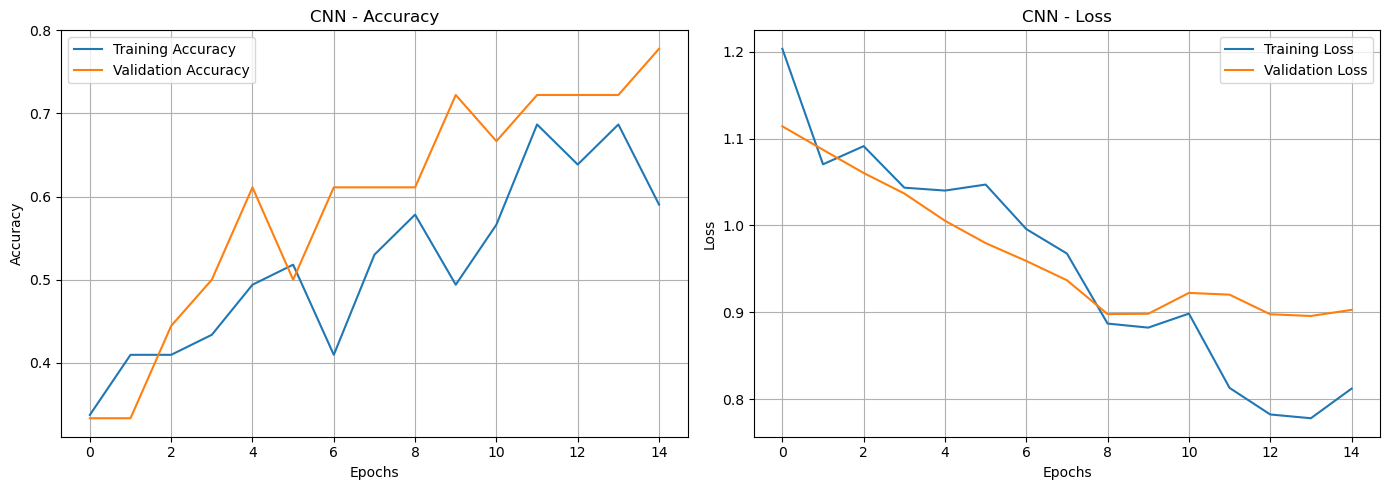

In [24]:
# Step 34: Visualize CNN Training and Validation Performance

plt.figure(figsize=(14, 5))

# Accuracy Graph
plt.subplot(1, 2, 1)

plt.plot(
    history_cnn.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history_cnn.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("CNN - Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

# Loss Graph
plt.subplot(1, 2, 2)

plt.plot(
    history_cnn.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_cnn.history["val_loss"],
    label="Validation Loss"
)

plt.title("CNN - Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


### CNN Model Training Performance Analysis

The Baseline CNN model was trained for 15 epochs using 83 training images and evaluated on 18 validation images.

### Final Training Results

- Training Accuracy: 59.04%
- Validation Accuracy: 77.78%
- Training Loss: 0.8121
- Validation Loss: 0.9028

### Observations

1. The training accuracy reached 59.04% by the final epoch.
2. The validation accuracy reached 77.78%.
3. Training loss decreased from 1.2033 to 0.8121.
4. Validation loss decreased initially but fluctuated during training.

### Conclusion

The Baseline CNN demonstrated learning during training and achieved 77.78% validation accuracy. However, the small dataset size and the difference between training and validation performance indicate that the model requires further evaluation on unseen data.

The final test evaluation and classification report will provide additional insights into the model's generalization ability.


In [39]:

# Step 36: Evaluate CNN model on test dataset

test_loss, test_accuracy = cnn_model.evaluate(
    X_test_scaled,
    y_test_encoded,
    verbose=1
)

print("\nCNN Model Test Results")
print("----------------------")
print("Test Loss:", round(test_loss, 4))
print("Test Accuracy:", round(test_accuracy * 100, 2), "%")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 119ms/step - accuracy: 0.5000 - loss: 0.9437

CNN Model Test Results
----------------------
Test Loss: 0.9437
Test Accuracy: 50.0 %


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 93ms/step


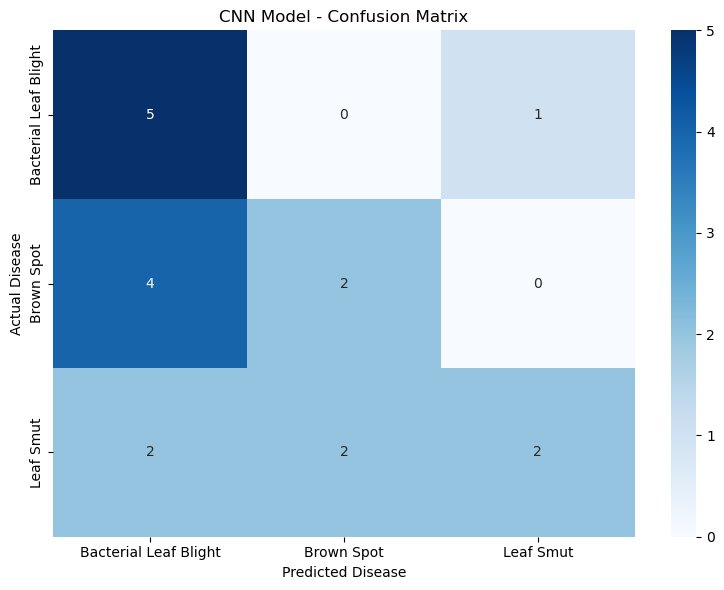

In [40]:

# Step 37: Generate CNN confusion matrix

y_test_pred_prob = cnn_model.predict(X_test_scaled)

y_test_pred = np.argmax(y_test_pred_prob, axis=1)

cm = confusion_matrix(
    y_test_encoded,
    y_test_pred
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title("CNN Model - Confusion Matrix")
plt.xlabel("Predicted Disease")
plt.ylabel("Actual Disease")
plt.tight_layout()
plt.show()

In [41]:

# Step 38: Generate CNN classification report

cnn_report = classification_report(
    y_test_encoded,
    y_test_pred,
    target_names=label_encoder.classes_,
    digits=4,
    zero_division=0
)

print("CNN Model - Classification Report")
print("----------------------------------")
print(cnn_report)

CNN Model - Classification Report
----------------------------------
                       precision    recall  f1-score   support

Bacterial Leaf Blight     0.4545    0.8333    0.5882         6
           Brown Spot     0.5000    0.3333    0.4000         6
            Leaf Smut     0.6667    0.3333    0.4444         6

             accuracy                         0.5000        18
            macro avg     0.5404    0.5000    0.4776        18
         weighted avg     0.5404    0.5000    0.4776        18



### CNN Model - Classification Report Analysis

The Baseline CNN achieved an overall test accuracy of 50.00% on 18 test images.

**Key observations:**

- Bacterial Leaf Blight achieved a recall of 83.33%.
- Brown Spot achieved a recall of 33.33%.
- Leaf Smut achieved a recall of 33.33%.
- The macro-average F1-score was 0.4776.
- The weighted-average F1-score was 0.4776.

The model performed better in identifying Bacterial Leaf Blight compared to Brown Spot and Leaf Smut.

The results indicate that the Baseline CNN has limitations in classifying all three disease categories consistently. Since the dataset contains only 119 images and the test set contains 18 images, the evaluation results should be interpreted cautiously.

Further experiments using Data Augmentation will be performed to investigate whether training with more varied image samples can improve model generalization.


## 9. Data Augmentation

Data augmentation is used to artificially increase the diversity of training images by applying transformations such as flipping, rotation, zooming, and translation.

Since the dataset contains only 119 images, augmentation is explored to improve the CNN model's ability to generalize to unseen rice leaf images.

Augmentation will be applied only to training images. Validation and test datasets will remain unchanged to prevent data leakage.


In [28]:


# Step 39: Improved Data Augmentation Layer

data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),

    layers.RandomRotation(
        0.05,
        fill_mode="reflect"
    ),

    layers.RandomZoom(
        0.10,
        fill_mode="reflect"
    ),

    layers.RandomTranslation(
        height_factor=0.05,
        width_factor=0.05,
        fill_mode="reflect"
    ),

    layers.RandomContrast(0.10),

    # Keep pixel values within the 0 to 1 range
    layers.Lambda(
        lambda x: tf.clip_by_value(x, 0.0, 1.0)
    )
], name="rice_leaf_data_augmentation")

print("Improved Data Augmentation Layer Created Successfully!")

Improved Data Augmentation Layer Created Successfully!


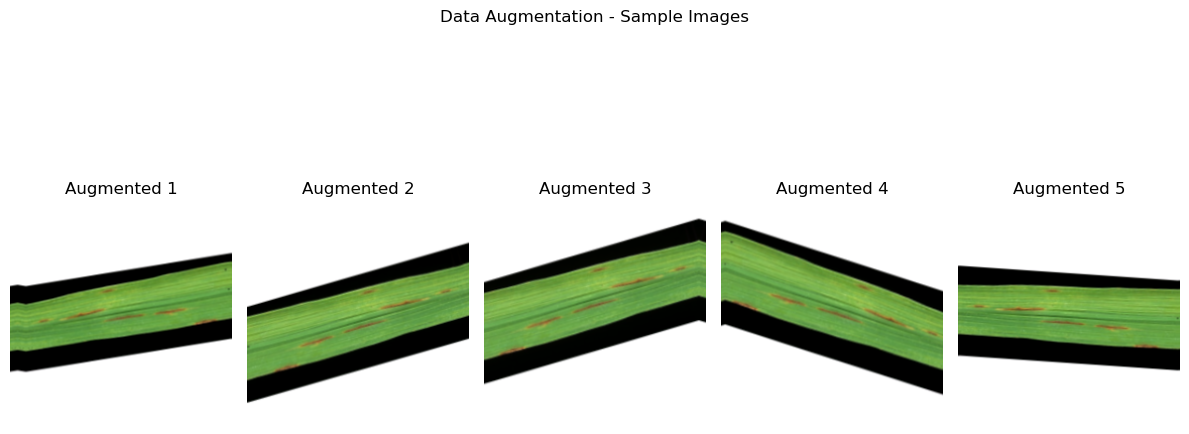

In [29]:

# Step 40: Visualize original and augmented images

sample_image = X_train_scaled[0]

plt.figure(figsize=(12, 6))

for i in range(5):
    augmented_image = data_augmentation(
        tf.expand_dims(sample_image, axis=0),
        training=True
    )[0].numpy()

    plt.subplot(1, 5, i + 1)
    plt.imshow(augmented_image)
    plt.axis("off")
    plt.title(f"Augmented {i+1}")

plt.suptitle("Data Augmentation - Sample Images")
plt.tight_layout()
plt.show()

In [30]:

# Step 41: Build Augmented CNN Model

augmented_cnn_model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),

    # Data Augmentation Layer
    data_augmentation,

    # CNN Architecture
    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),

    layers.Dense(3, activation="softmax")
])

# Display model architecture
augmented_cnn_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ rice_leaf_data_augmentation          │ (None, 224, 224, 3)         │               0 │
│ (Sequential)                         │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_3 (Conv2D)                    │ (None, 224, 224, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 112, 112, 32)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_4 (Conv2D)                    │ (None, 112, 112, 64)        │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_4 (MaxPooling2D)       │ (None, 56, 56, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_5 (Conv2D)                    │ (None, 56, 56, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_5 (MaxPooling2D)       │ (None, 28, 28, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_1 (Flatten)                  │ (None, 100352)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 128)                 │      12,845,184 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 3)                   │             387 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 12,938,819 (49.36 MB)

 Trainable params: 12,938,819 (49.36 MB)

 Non-trainable params: 0 (0.00 B)

In [31]:

# Step 42: Compile Augmented CNN Model

augmented_cnn_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Augmented CNN Model Compiled Successfully!")

Augmented CNN Model Compiled Successfully!


In [32]:

# Step 43: Train Augmented CNN Model

history_augmented = augmented_cnn_model.fit(
    X_train_scaled,
    y_train_encoded,
    validation_data=(X_val_scaled, y_val_encoded),
    epochs=15,
    batch_size=8,
    verbose=1
)

Epoch 1/15
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 186ms/step - accuracy: 0.3614 - loss: 1.2124 - val_accuracy: 0.3333 - val_loss: 1.1430
Epoch 2/15
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 172ms/step - accuracy: 0.3735 - loss: 1.1291 - val_accuracy: 0.3333 - val_loss: 1.1074
Epoch 3/15
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 169ms/step - accuracy: 0.3614 - loss: 1.1268 - val_accuracy: 0.3333 - val_loss: 1.0903
Epoch 4/15
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 177ms/step - accuracy: 0.3976 - loss: 1.0929 - val_accuracy: 0.3333 - val_loss: 1.0829
Epoch 5/15
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 166ms/step - accuracy: 0.3373 - loss: 1.1109 - val_accuracy: 0.5556 - val_loss: 1.0801
Epoch 6/15
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 172ms/step - accuracy: 0.3614 - loss: 1.0882 - val_accuracy: 0.4444 - val_loss: 1.0687
Epoch 7/15
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 172ms/step - accuracy: 0.4819 - loss: 1.0626 - val_accuracy: 0.3889 - val_loss: 1.0485
Epoch 8/15
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 175ms/step - accuracy: 0.3855 - loss: 1.0740 - val_accuracy: 0.

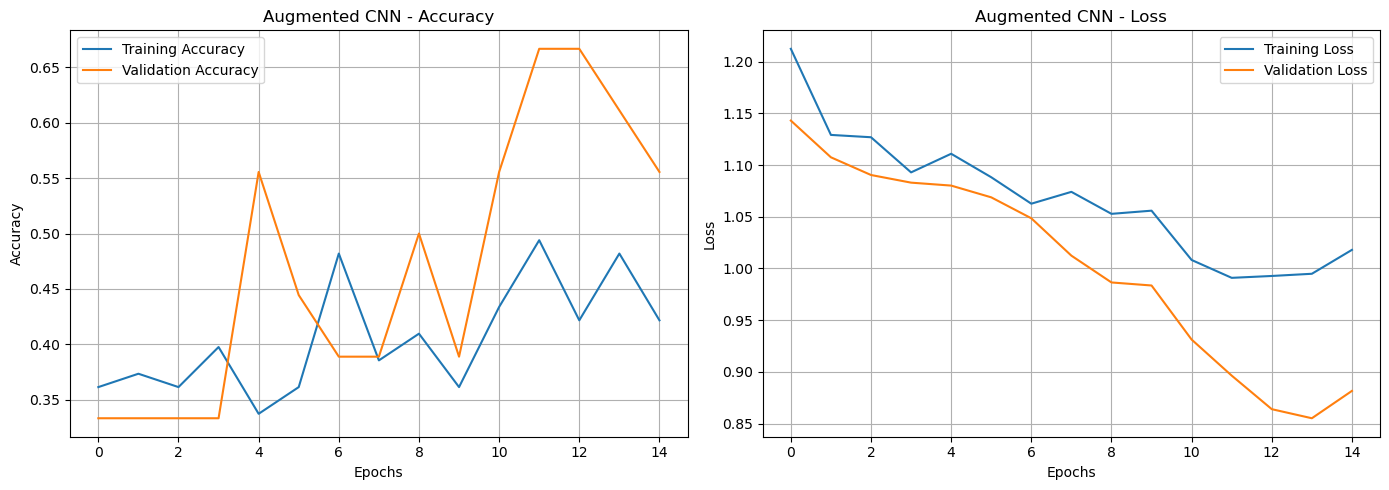

In [33]:
# Step 44: Augmented CNN Accuracy and Loss Graphs

plt.figure(figsize=(14, 5))

# Accuracy Graph
plt.subplot(1, 2, 1)
plt.plot(history_augmented.history["accuracy"],
         label="Training Accuracy")
plt.plot(history_augmented.history["val_accuracy"],
         label="Validation Accuracy")

plt.title("Augmented CNN - Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

# Loss Graph
plt.subplot(1, 2, 2)
plt.plot(history_augmented.history["loss"],
         label="Training Loss")
plt.plot(history_augmented.history["val_loss"],
         label="Validation Loss")

plt.title("Augmented CNN - Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [34]:
# Step 45: Evaluate Augmented CNN Model

augmented_test_loss, augmented_test_accuracy = augmented_cnn_model.evaluate(
    X_test_scaled,
    y_test_encoded,
    verbose=1
)

print("\nAugmented CNN Model - Test Results")
print("---------------------------------")
print(f"Test Loss     : {augmented_test_loss:.4f}")
print(f"Test Accuracy : {augmented_test_accuracy:.4f}")
print(f"Test Accuracy : {augmented_test_accuracy * 100:.2f}%")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 104ms/step - accuracy: 0.5000 - loss: 1.0115

Augmented CNN Model - Test Results
---------------------------------
Test Loss     : 1.0115
Test Accuracy : 0.5000
Test Accuracy : 50.00%


In [35]:
# Step 46: Augmented CNN Classification Report

augmented_y_pred = augmented_cnn_model.predict(
    X_test_scaled,
    verbose=0
)

augmented_y_pred_classes = np.argmax(
    augmented_y_pred,
    axis=1
)

class_names = [
    "Bacterial Leaf Blight",
    "Brown Spot",
    "Leaf Smut"
]

print("Augmented CNN - Classification Report")
print("------------------------------------")

print(classification_report(
    y_test_encoded,
    augmented_y_pred_classes,
    target_names=class_names,
    digits=4,
    zero_division=0
))

Augmented CNN - Classification Report
------------------------------------
                       precision    recall  f1-score   support

Bacterial Leaf Blight     0.4286    1.0000    0.6000         6
           Brown Spot     0.6667    0.3333    0.4444         6
            Leaf Smut     1.0000    0.1667    0.2857         6

             accuracy                         0.5000        18
            macro avg     0.6984    0.5000    0.4434        18
         weighted avg     0.6984    0.5000    0.4434        18



### Augmented CNN - Classification Report Analysis

The Augmented CNN achieved an overall test accuracy of 50.00% on 18 test images.

**Key observations:**

- Bacterial Leaf Blight achieved a recall of 100%, correctly identifying all 6 actual test images.
- Brown Spot achieved a recall of 33.33%.
- Leaf Smut achieved a recall of 16.67%.
- The macro-average F1-score was 0.4434.
- The weighted-average F1-score was 0.4434.

The model performed best in identifying Bacterial Leaf Blight. However, it struggled to correctly classify Brown Spot and Leaf Smut images.

The results indicate that data augmentation did not improve the overall test accuracy in this experiment. The limited dataset size and the small number of test images may have affected model performance.

Further improvements through additional data collection, model tuning, and experimentation with different augmentation strategies may help improve classification performance.

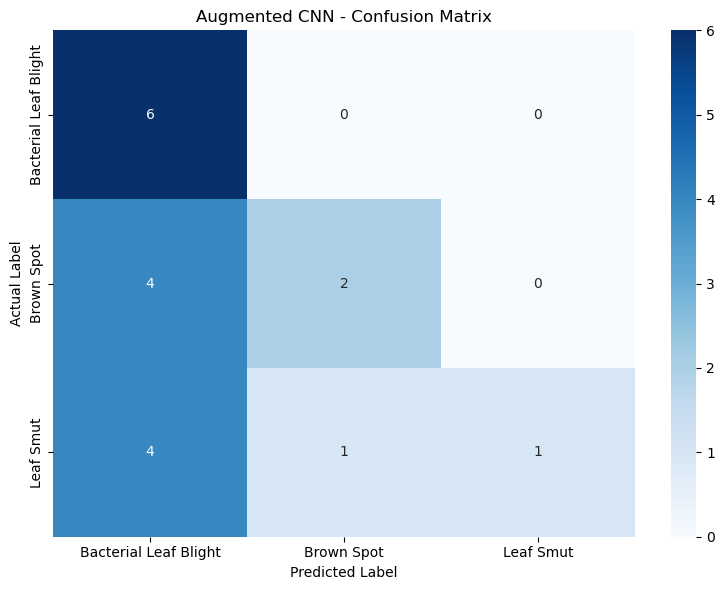

In [42]:
# Step 47: Augmented CNN Confusion Matrix

augmented_cm = confusion_matrix(
    y_test_encoded,
    augmented_y_pred_classes
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    augmented_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Augmented CNN - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

In [43]:

# Step 48: CNN Model Performance Comparison

model_comparison = pd.DataFrame({
    "Metric": [
        "Training Accuracy",
        "Validation Accuracy",
        "Test Accuracy",
        "Test Loss",
        "Macro F1-Score"
    ],
    "Baseline CNN": [
        59.04,
        77.78,
        50.00,
        0.9437,
        0.4776
    ],
    "Augmented CNN": [
        42.17,
        55.56,
        50.00,
        1.0115,
        0.4434
    ]
})

print("CNN Model Performance Comparison")
print("--------------------------------")
display(model_comparison)

CNN Model Performance Comparison
--------------------------------


,Metric,Baseline CNN,Augmented CNN
0,Training Accuracy,59.0400,42.1700
1,Validation Accuracy,77.7800,55.5600
2,Test Accuracy,50.0000,50.0000
3,Test Loss,0.9437,1.0115
4,Macro F1-Score,0.4776,0.4434


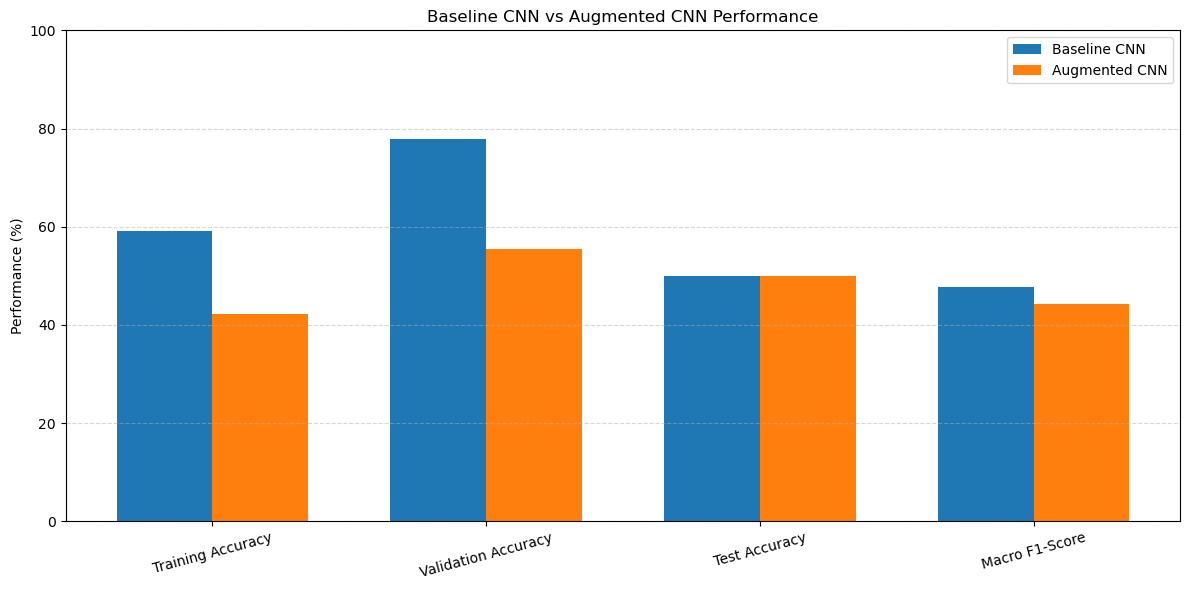

In [44]:

# Step 49: CNN Model Comparison Visualization

metrics_to_compare = [
    "Training Accuracy",
    "Validation Accuracy",
    "Test Accuracy",
    "Macro F1-Score"
]

baseline_values = [59.04, 77.78, 50.00, 47.76]
augmented_values = [42.17, 55.56, 50.00, 44.34]

x = np.arange(len(metrics_to_compare))
width = 0.35

plt.figure(figsize=(12, 6))

plt.bar(
    x - width/2,
    baseline_values,
    width,
    label="Baseline CNN"
)

plt.bar(
    x + width/2,
    augmented_values,
    width,
    label="Augmented CNN"
)

plt.xticks(x, metrics_to_compare, rotation=15)
plt.ylabel("Performance (%)")
plt.title("Baseline CNN vs Augmented CNN Performance")
plt.ylim(0, 100)

plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

## Model Comparison Report

Two CNN model configurations were evaluated for rice leaf disease classification: a Baseline CNN and an Augmented CNN. Both models were evaluated using training accuracy, validation accuracy, test accuracy, test loss, and Macro F1-Score.

### Performance Comparison

The Baseline CNN achieved a test accuracy of 50.00%, while the Augmented CNN also achieved a test accuracy of 50.00%. Therefore, data augmentation did not improve the overall test accuracy in this experiment.

The Baseline CNN achieved a Macro F1-Score of 0.4776, compared to 0.4434 for the Augmented CNN. The Baseline CNN also demonstrated higher validation accuracy and lower test loss.

### Key Observations

- The Baseline CNN achieved higher training accuracy (59.04%) than the Augmented CNN (42.17%).
- The Baseline CNN achieved higher validation accuracy (77.78%) than the Augmented CNN (55.56%).
- Both models achieved the same test accuracy of 50.00%.
- The Baseline CNN achieved a higher Macro F1-Score (0.4776) than the Augmented CNN (0.4434).
- Data augmentation did not improve the overall test performance of the model.
- Both models showed limitations in classifying all three disease categories consistently.
- The small dataset size may have affected model generalization and performance stability.

### Conclusion

Based on the experimental results, the Baseline CNN demonstrated better overall performance than the Augmented CNN in terms of validation accuracy, test loss, and Macro F1-Score. Both models achieved the same test accuracy.

Although data augmentation was introduced to improve generalization, it did not produce better results in this experiment. The Baseline CNN is therefore considered the better-performing configuration among the two evaluated models.

Further improvements may require a larger and more diverse dataset, additional model tuning, and more extensive evaluation before practical deployment.

## Challenges Report

### 1. Limited Dataset Size

**Challenge:** The dataset contained only 119 images across three disease classes, which limited the model's ability to learn diverse image patterns.

**Solution:** Data augmentation techniques such as rotation, horizontal flipping, zooming, and shifting were applied to increase the diversity of training images.

**Reason:** Augmentation introduces variations into the training images and may help reduce overfitting. However, it cannot completely compensate for the limited number of original images.

### 2. Image Variations

**Challenge:** Images differed in lighting conditions, orientation, background, and leaf appearance.

**Solution:** Images were resized to a uniform dimension of 224 × 224 pixels and normalized before model training.

**Reason:** Standardizing image dimensions and pixel values helps the CNN process images consistently.

### 3. Model Generalization

**Challenge:** Both CNN models showed limited performance on unseen test images, achieving a test accuracy of 50.00%.

**Solution:** The dataset was divided into training, validation, and testing sets. Data augmentation was applied to the training data.

**Reason:** Separate datasets help evaluate the model's ability to generalize to unseen images, while augmentation introduces additional training variations.

### 4. Class-Wise Classification Performance

**Challenge:** Both models showed inconsistent classification performance across the three disease classes. The Baseline CNN achieved a recall of 33.33% for Brown Spot and Leaf Smut, while the Augmented CNN achieved a recall of 33.33% for Brown Spot and 16.67% for Leaf Smut.

**Solution:** Classification reports and confusion matrices were used to identify class-wise performance issues.

**Reason:** Overall accuracy alone cannot reveal whether the model performs poorly on a particular disease class. Class-wise metrics provide a more detailed understanding of model performance.

### 5. Computational Limitations

**Challenge:** Training deep learning models using limited computational resources can increase training time.

**Solution:** A relatively simple CNN architecture was implemented and trained using a limited number of epochs.

**Reason:** A lightweight model makes experimentation practical while allowing performance evaluation within the available computing environment.

### Conclusion

The project demonstrated the importance of data quality, preprocessing, augmentation, class-wise evaluation, and model comparison. The limited dataset size remains the primary challenge. Collecting more diverse, high-quality rice leaf images and performing further model optimization would be essential for improving classification performance.

## Final Model Selection

Based on the experimental evaluation, the Baseline CNN was selected as the better-performing model compared to the Augmented CNN.

The Baseline CNN achieved a test accuracy of 50.00% and a Macro F1-Score of 0.4776, whereas the Augmented CNN achieved a test accuracy of 50.00% and a Macro F1-Score of 0.4434.

The Baseline CNN also achieved higher validation accuracy (77.78%) compared to the Augmented CNN (55.56%).

Although data augmentation was applied using horizontal flipping, rotation, zooming, translation, and contrast adjustment, it did not improve the overall test performance in this experiment.

The Baseline CNN demonstrated better performance in validation accuracy, test loss, and Macro F1-Score, while both models achieved the same test accuracy.

Therefore, the Baseline CNN was selected as the better-performing model for this rice leaf disease classification experiment. However, its performance can be further improved by collecting more images, applying transfer learning, and tuning hyperparameters.

## Data Augmentation Techniques Analysis

Data augmentation was applied to the training images to increase the diversity of the dataset and help the CNN model learn different variations of rice leaf disease patterns.

The following augmentation techniques were used:

1. **Horizontal Flip:** Flips images horizontally to introduce variations in leaf orientation.
2. **Random Rotation:** Rotates images slightly to simulate different image angles.
3. **Random Zoom:** Zooms in or out to introduce variations in leaf size and positioning.
4. **Random Translation:** Shifts images horizontally and vertically.
5. **Random Contrast:** Adjusts image contrast to simulate different lighting conditions.

### Augmentation Experiment Results

The Baseline CNN achieved a test accuracy of 50.00%, while the Augmented CNN also achieved a test accuracy of 50.00%.

The Baseline CNN achieved a Macro F1-Score of 0.4776, compared to 0.4434 for the Augmented CNN.

The augmentation experiment did not improve the overall test accuracy or Macro F1-Score. The limited number of training images may have restricted the model's ability to learn meaningful disease patterns from augmented samples.

### Conclusion

Data augmentation introduced image variations during training, but it did not improve classification performance in this experiment. The Baseline CNN performed better in terms of validation accuracy and Macro F1-Score.

Further experimentation with augmentation parameters, additional training images, transfer learning, and hyperparameter tuning may help improve the model's performance.

# Final Conclusion

This project focused on analyzing and classifying rice leaf diseases using image processing and Convolutional Neural Networks (CNNs).

The dataset consisted of 119 images belonging to three disease categories: Bacterial Leaf Blight, Brown Spot, and Leaf Smut. Exploratory Data Analysis was performed to understand the dataset, image characteristics, RGB distributions, and class-wise image distribution.

Image preprocessing techniques, including resizing and normalization, were applied to prepare the images for model training. A Baseline CNN was developed and evaluated, followed by an Augmented CNN using data augmentation techniques to investigate their impact on model performance.

### Model Performance

- Baseline CNN Test Accuracy: 50.00%
- Augmented CNN Test Accuracy: 50.00%
- Baseline CNN Macro F1-Score: 0.4776
- Augmented CNN Macro F1-Score: 0.4434

Both models achieved the same test accuracy. However, the Baseline CNN demonstrated better validation accuracy and Macro F1-Score than the Augmented CNN.

Class-wise evaluation revealed that both models struggled to consistently classify all three disease categories, particularly Brown Spot and Leaf Smut.

### Key Learnings

- Image preprocessing is essential for consistent model training.
- Data augmentation introduces image variations but does not always improve model performance.
- CNNs can extract visual features useful for image classification.
- Confusion matrices and classification reports provide deeper insights than accuracy alone.
- Dataset size and diversity significantly influence model performance.
- Comparing multiple model configurations helps identify the most suitable approach for a given dataset.

### Limitations and Future Improvements

The dataset was relatively small, limiting the models' ability to generalize to unseen images. Future improvements could include collecting more images under diverse environmental conditions, experimenting with advanced CNN architectures and transfer learning, tuning hyperparameters, and evaluating models on larger independent datasets.

### Final Outcome

The project successfully implemented an end-to-end rice leaf disease classification workflow involving data analysis, preprocessing, CNN model development, data augmentation, and performance evaluation.

The Baseline CNN was selected as the better-performing configuration in this experiment based on its higher validation accuracy and Macro F1-Score. However, both models achieved only 50.00% test accuracy and are not considered production-ready.

Further development, additional training data, and extensive validation are required before using these models for practical agricultural disease diagnosis.